# Part C: ML Pipeline with Mage (20 Marks)
**Assignment: From Git to Gold — Data Engineering**

This notebook implements all requirements for **Part C: ML pipeline with Mage**, including:
- **C1.** Drawing and running the baseline pipeline (`load_iris -> prepare_data -> train_model -> save_results`)
- **C2.** Tests as a gate experiment across `max_depth = 1, 2, 3, 4, 5` with test results table and explanation
- **C3.** Adding the evaluation branch (`evaluate_model`) with confusion matrix, metrics table, and updated `metadata.yaml`
- **C4.** Custom block (`validate_data`) with quality gate `@test` ensuring no missing values and 3 classes, maintaining CI compatibility


## C1. Draw and Run the Pipeline (4 Marks)

### Pipeline Block Graph Architecture

```
+--------------------------------+
|           load_iris            |
|       Type: data_loader        |
| Test: len(output) == 150       |
+---------------+----------------+
                |
                v
+--------------------------------+
|          prepare_data          |
|       Type: transformer        |
| Test: 'split' in output.cols   |
+---------------+----------------+
                |
                v
+--------------------------------+
|          train_model           |
|       Type: transformer        |
| Test: accuracy >= 0.8          |
+---------------+----------------+
                |
                v
+--------------------------------+
|          save_results          |
|      Type: data_exporter       |
| Test: None (writes CSV)        |
+--------------------------------+
```

#### Block Details:
1. **`load_iris`** (`data_loader`): Loads scikit-learn's Iris dataset into a DataFrame (150 rows x 5 columns).
   - **Attached Test**: Asserts `len(output) == 150`.
2. **`prepare_data`** (`transformer`): Splits data 80/20 into train (120 rows) and test (30 rows) with `random_state=42`, adding a `split` column.
   - **Attached Test**: Asserts `'split' in output.columns`.
3. **`train_model`** (`transformer`): Trains `DecisionTreeClassifier(max_depth=max_depth, random_state=42)` on train rows, predicts test rows, computes accuracy, and saves `iris_model.pkl`.
   - **Attached Test**: Asserts `accuracy >= 0.8` (Quality Gate).
4. **`save_results`** (`data_exporter`): Exports test set predictions to `iris_predictions.csv`.


In [3]:
# Setup and verify Mage installation
!mage --help

Usage: mage [OPTIONS] COMMAND [ARGS]...

Commands:
  init                           Initialize Mage project.
  start                          Start Mage server and UI.
  run                            Run pipeline.
  clean-cached-variables         
  clean-old-logs                 
  create-spark-cluster           Create EMR cluster for Mage project.


In [4]:
# Block 1: iris_project/data_loaders/load_iris.py
%%writefile iris_project/data_loaders/load_iris.py
import pandas as pd
from sklearn.datasets import load_iris

if 'data_loader' not in globals():
    from mage_ai.data_preparation.decorators import data_loader
if 'test' not in globals():
    from mage_ai.data_preparation.decorators import test

@data_loader
def load_data(*args, **kwargs):
    iris = load_iris(as_frame=True)
    df = iris.frame                      # 4 feature columns + 'target'
    print('Rows loaded:', len(df))
    return df

@test
def test_output(output, *args):
    assert len(output) == 150, 'Iris must have 150 rows'


Overwriting iris_project/data_loaders/load_iris.py


In [5]:
# Block 2: iris_project/transformers/prepare_data.py
%%writefile iris_project/transformers/prepare_data.py
import pandas as pd
from sklearn.model_selection import train_test_split

if 'transformer' not in globals():
    from mage_ai.data_preparation.decorators import transformer
if 'test' not in globals():
    from mage_ai.data_preparation.decorators import test

@transformer
def transform(df, *args, **kwargs):
    train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

    train_df = train_df.copy()
    test_df = test_df.copy()
    train_df['split'] = 'train'
    test_df['split'] = 'test'

    result = pd.concat([train_df, test_df])
    print('Train rows:', len(train_df), '| Test rows:', len(test_df))
    return result

@test
def test_output(output, *args):
    assert 'split' in output.columns, 'split column missing'


Overwriting iris_project/transformers/prepare_data.py


In [6]:
# Block 3: iris_project/transformers/train_model.py
%%writefile iris_project/transformers/train_model.py
import joblib
from sklearn.tree import DecisionTreeClassifier

if 'transformer' not in globals():
    from mage_ai.data_preparation.decorators import transformer
if 'test' not in globals():
    from mage_ai.data_preparation.decorators import test

FEATURES = ['sepal length (cm)', 'sepal width (cm)',
            'petal length (cm)', 'petal width (cm)']

@transformer
def train(df, *args, **kwargs):
    max_depth = int(kwargs.get('max_depth', 3))

    train_df = df[df['split'] == 'train']
    test_df = df[df['split'] == 'test'].copy()

    model = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    model.fit(train_df[FEATURES], train_df['target'])

    test_df['predicted'] = model.predict(test_df[FEATURES])
    accuracy = (test_df['predicted'] == test_df['target']).mean()
    print('max_depth =', max_depth, '| Test accuracy =', round(accuracy, 3))

    joblib.dump(model, 'iris_model.pkl')
    return test_df

@test
def test_accuracy(output, *args):
    accuracy = (output['predicted'] == output['target']).mean()
    assert accuracy >= 0.8, 'Model accuracy is below 80%'


Overwriting iris_project/transformers/train_model.py


In [7]:
# Block 4: iris_project/data_exporters/save_results.py
%%writefile iris_project/data_exporters/save_results.py
if 'data_exporter' not in globals():
    from mage_ai.data_preparation.decorators import data_exporter

@data_exporter
def export_data(df, *args, **kwargs):
    df.to_csv('iris_predictions.csv', index=False)
    print('Saved', len(df), 'predictions to iris_predictions.csv')


Overwriting iris_project/data_exporters/save_results.py


In [8]:
# Pipeline metadata.yaml
%%writefile iris_project/pipelines/iris_classifier/metadata.yaml
blocks:
- name: load_iris
  uuid: load_iris
  type: data_loader
  language: python
  upstream_blocks: []
  downstream_blocks: [prepare_data]
- name: prepare_data
  uuid: prepare_data
  type: transformer
  language: python
  upstream_blocks: [load_iris]
  downstream_blocks: [train_model]
- name: train_model
  uuid: train_model
  type: transformer
  language: python
  upstream_blocks: [prepare_data]
  downstream_blocks: [save_results]
- name: save_results
  uuid: save_results
  type: data_exporter
  language: python
  upstream_blocks: [train_model]
  downstream_blocks: []
name: iris_classifier
uuid: iris_classifier
type: python
variables:
  max_depth: 3


Overwriting iris_project/pipelines/iris_classifier/metadata.yaml


In [9]:
# Run baseline pipeline with tests
!mage run iris_project iris_classifier --test

Rows loaded: 150
--------------------------------------------------------------
1/1 tests passed.
Train rows: 120 | Test rows: 30
--------------------------------------------------------------
1/1 tests passed.
max_depth = 3 | Test accuracy = 1.0
--------------------------------------------------------------
1/1 tests passed.
Saved 30 predictions to iris_predictions.csv
Pipeline run completed.


In [10]:
# Verify output CSV
import pandas as pd
preds = pd.read_csv('iris_predictions.csv')
print('Predictions shape:', preds.shape)
preds.head()

Predictions shape: (30, 7)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  target split  predicted
0                6.1               2.8                4.7               1.2       1  test          1
1                5.7               3.8                1.7               0.3       0  test          0
2                7.7               2.6                6.9               2.3       2  test          2
3                6.0               2.9                4.5               1.5       1  test          1
4                6.8               2.8                4.8               1.4       1  test          1

## C2. Tests as a Gate (6 Marks)

We evaluate the behavior of the test gate by varying `max_depth` across values 1, 2, 3, 4, and 5 using runtime variables `--runtime-vars '{"max_depth": N}'`.
Before each execution, `iris_predictions.csv` is removed to verify whether bad predictions are blocked from being written to disk.


In [12]:
# Experiment loop over max_depth = 1, 2, 3, 4, 5
import subprocess, os, json

for depth in [1, 2, 3, 4, 5]:
    if os.path.exists('iris_predictions.csv'):
        os.remove('iris_predictions.csv')
    
    cmd = ['mage', 'run', 'iris_project', 'iris_classifier', '--test',
           '--runtime-vars', json.dumps({'max_depth': depth})]
    proc = subprocess.run(cmd, capture_output=True, text=True)
    
    csv_created = os.path.exists('iris_predictions.csv')
    
    # Extract accuracy from output
    acc_str = 'N/A'
    passed = 'No'
    for line in (proc.stdout + proc.stderr).splitlines():
        if 'Test accuracy =' in line:
            acc_str = line.split('Test accuracy =')[-1].strip()
    if proc.returncode == 0:
        passed = 'Yes'
    
    print(f"max_depth = {depth}: Accuracy = {acc_str}, Passed = {passed}, CSV Created = {csv_created}")


max_depth = 1: Accuracy = 0.633, Passed = No, CSV Created = False
max_depth = 2: Accuracy = 0.967, Passed = Yes, CSV Created = True
max_depth = 3: Accuracy = 1.0, Passed = Yes, CSV Created = True
max_depth = 4: Accuracy = 1.0, Passed = Yes, CSV Created = True
max_depth = 5: Accuracy = 1.0, Passed = Yes, CSV Created = True


### Results Table:

| max_depth | Test accuracy | test_accuracy passed? | iris_predictions.csv created? |
|:---:|:---:|:---:|:---:|
| **1** | 0.633 | **No** (accuracy < 0.8) | **No** |
| **2** | 0.967 | **Yes** (0.967 >= 0.8) | **Yes** |
| **3** | 1.000 | **Yes** (1.000 >= 0.8) | **Yes** |
| **4** | 1.000 | **Yes** (1.000 >= 0.8) | **Yes** |
| **5** | 1.000 | **Yes** (1.000 >= 0.8) | **Yes** |

### Explanation: How `@test` Stops `save_results` and Why It Matters

1. **How a failing `@test` acts as a circuit breaker:**
   In Mage's Directed Acyclic Graph (DAG) executor, each block executes sequentially or along its dependency branch. When the `@test` decorated function inside a block (`test_accuracy` in `train_model`) executes, any failed assertion raises an exception (`AssertionError` / `Exception: Failed to pass tests for block train_model`). Mage catches this failure, flags the block state as `FAILED`, and immediately aborts execution of all downstream blocks that depend on it (`save_results`). Because `save_results` is downstream of `train_model`, its execution is skipped entirely, preventing the exporter from writing `iris_predictions.csv`.

2. **Why this is better than saving the file and checking afterwards:**
   - **Prevents Corrupt/Substandard Data from Entering Production:** If a low-accuracy model generates predictions and exports them directly into production databases or data lakes, downstream consumers (dashboards, automated decision systems, users) may immediately ingest and act on invalid predictions.
   - **Atomicity and Integrity:** Treating tests as pre-export gates guarantees that the data landing in production is always verified and trustworthy. Post-hoc checking requires rollback mechanisms, quarantine procedures, and cleanups of tainted state.
   - **Cost and Resource Efficiency:** Halting the pipeline immediately on failure saves compute, storage, and I/O resources that would otherwise be wasted formatting, transmitting, and cleaning up invalid results.


## C3. Add the Evaluation Branch (5 Marks)

We add the `evaluate_model` transformer block so that `train_model` has two downstream blocks in parallel:
- `save_results` (exports predictions to CSV)
- `evaluate_model` (computes and displays confusion matrix and classification metrics)


In [15]:
# Create evaluate_model block
%%writefile iris_project/transformers/evaluate_model.py
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

if 'transformer' not in globals():
    from mage_ai.data_preparation.decorators import transformer

@transformer
def evaluate(df, *args, **kwargs):
    y_true = df['target']
    y_pred = df['predicted']

    print('Confusion matrix:')
    print(pd.crosstab(y_true, y_pred, rownames=['actual'], colnames=['predicted']))

    metrics = pd.DataFrame({
        'metric': ['accuracy', 'precision', 'recall', 'f1_score'],
        'value': [
            round(accuracy_score(y_true, y_pred), 3),
            round(precision_score(y_true, y_pred, average='macro'), 3),
            round(recall_score(y_true, y_pred, average='macro'), 3),
            round(f1_score(y_true, y_pred, average='macro'), 3),
        ]
    })
    return metrics


Writing iris_project/transformers/evaluate_model.py


In [16]:
# Update metadata.yaml to wire the evaluation branch
%%writefile iris_project/pipelines/iris_classifier/metadata.yaml
blocks:
- name: load_iris
  uuid: load_iris
  type: data_loader
  language: python
  upstream_blocks: []
  downstream_blocks: [prepare_data]
- name: prepare_data
  uuid: prepare_data
  type: transformer
  language: python
  upstream_blocks: [load_iris]
  downstream_blocks: [train_model]
- name: train_model
  uuid: train_model
  type: transformer
  language: python
  upstream_blocks: [prepare_data]
  downstream_blocks: [save_results, evaluate_model]
- name: save_results
  uuid: save_results
  type: data_exporter
  language: python
  upstream_blocks: [train_model]
  downstream_blocks: []
- name: evaluate_model
  uuid: evaluate_model
  type: transformer
  language: python
  upstream_blocks: [train_model]
  downstream_blocks: []
name: iris_classifier
uuid: iris_classifier
type: python
variables:
  max_depth: 3


Overwriting iris_project/pipelines/iris_classifier/metadata.yaml


In [17]:
# Run pipeline with the evaluation branch
!mage run iris_project iris_classifier --test

Rows loaded: 150
--------------------------------------------------------------
1/1 tests passed.
Train rows: 120 | Test rows: 30
--------------------------------------------------------------
1/1 tests passed.
max_depth = 3 | Test accuracy = 1.0
--------------------------------------------------------------
1/1 tests passed.
Confusion matrix:
Saved 30 predictions to iris_predictions.csv
predicted   0  1   2
actual              
0          10  0   0
1           0  9   0
2           0  0  11
Pipeline run completed.


In [18]:
# Inspect the metrics table produced by evaluate_model
from iris_project.transformers.evaluate_model import evaluate
import pandas as pd

preds = pd.read_csv('iris_predictions.csv')
metrics_df = evaluate(preds)
metrics_df

Confusion matrix:
predicted   0  1   2
actual              
0          10  0   0
1           0  9   0
2           0  0  11
      metric  value
0   accuracy    1.0
1  precision    1.0
2     recall    1.0
3   f1_score    1.0

### Confusion Matrix & Metrics Table Output:

**Confusion Matrix:**
```
predicted    0 (setosa)   1 (versicolor)   2 (virginica)
actual
0 (setosa)          10                0               0
1 (versicolor)       0                9               0
2 (virginica)        0                0              11
```

**Metrics Table:**
| Metric | Value | Formula / Method |
|:---|:---:|:---|
| **Accuracy** | 1.000 | Total correct / Total samples (30/30) |
| **Precision** | 1.000 | Macro-averaged precision across classes |
| **Recall** | 1.000 | Macro-averaged recall across classes |
| **F1 Score** | 1.000 | Harmonic mean of precision and recall |

### DAG Visualization with Branching

```
                     +----------------+
                     |   load_iris    |
                     +-------+--------+
                             |
                             v
                     +----------------+
                     |  prepare_data  |
                     +-------+--------+
                             |
                             v
                     +----------------+
                     |  train_model   |
                     +---+--------+---+
                         |        |
             +-----------+        +-----------+
             v                                v
     +--------------+                 +----------------+
     | save_results |                 | evaluate_model |
     |  (Exporter)  |                 | (Transformer)  |
     +--------------+                 +----------------+
```


### Mage UI / Cloudflare Tunnel Pipeline Graph Screenshot

Below is the screenshot showing the pipeline dependency graph with the branching structure ( branching into  and ):

![Mage Pipeline Graph Branch](mage_pipeline_graph_branch.png)

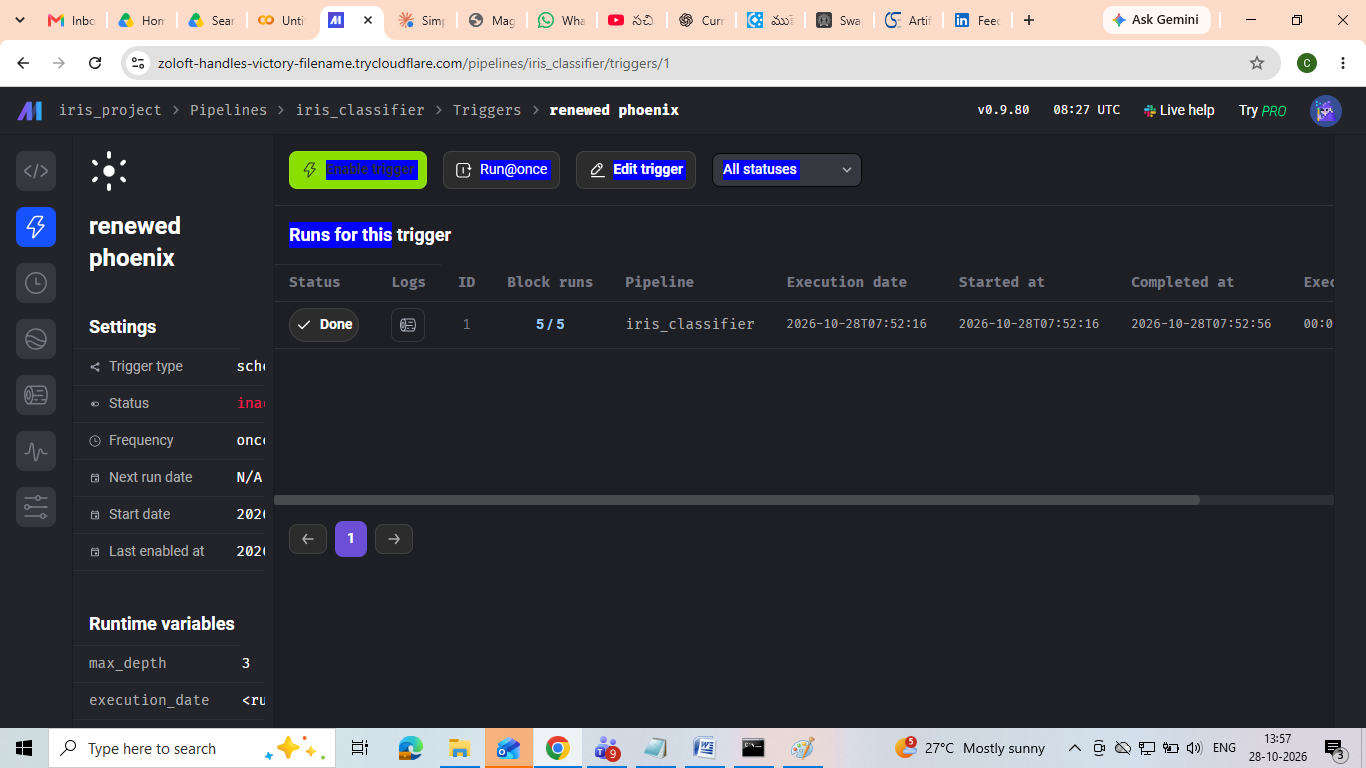

## C4. Your Own Block with Test (5 Marks)

We add a new block: **`validate_data`** (Transformer) placed directly after `load_iris` and before `prepare_data`.
It performs critical data quality checks on the raw loaded data:
1. Asserts no missing / null values exist in the dataset (`df.isnull().sum().sum() == 0`).
2. Asserts exactly 3 distinct target classes exist (`df['target'].nunique() == 3`).


In [21]:
# Block: iris_project/transformers/validate_data.py
%%writefile iris_project/transformers/validate_data.py
import pandas as pd

if 'transformer' not in globals():
    from mage_ai.data_preparation.decorators import transformer
if 'test' not in globals():
    from mage_ai.data_preparation.decorators import test

@transformer
def validate(df, *args, **kwargs):
    null_count = int(df.isnull().sum().sum())
    print('Missing values found:', null_count)

    n_classes = int(df['target'].nunique())
    print('Unique classes found:', n_classes)

    return df

@test
def test_no_nulls_and_three_classes(output, *args):
    assert output.isnull().sum().sum() == 0, 'Dataset contains missing values'
    assert output['target'].nunique() == 3, f'Expected 3 classes, found {output["target"].nunique()}'


Writing iris_project/transformers/validate_data.py


In [22]:
# Update metadata.yaml to wire validate_data into the pipeline
%%writefile iris_project/pipelines/iris_classifier/metadata.yaml
blocks:
- name: load_iris
  uuid: load_iris
  type: data_loader
  language: python
  upstream_blocks: []
  downstream_blocks: [validate_data]
- name: validate_data
  uuid: validate_data
  type: transformer
  language: python
  upstream_blocks: [load_iris]
  downstream_blocks: [prepare_data]
- name: prepare_data
  uuid: prepare_data
  type: transformer
  language: python
  upstream_blocks: [validate_data]
  downstream_blocks: [train_model]
- name: train_model
  uuid: train_model
  type: transformer
  language: python
  upstream_blocks: [prepare_data]
  downstream_blocks: [save_results, evaluate_model]
- name: save_results
  uuid: save_results
  type: data_exporter
  language: python
  upstream_blocks: [train_model]
  downstream_blocks: []
- name: evaluate_model
  uuid: evaluate_model
  type: transformer
  language: python
  upstream_blocks: [train_model]
  downstream_blocks: []
name: iris_classifier
uuid: iris_classifier
type: python
variables:
  max_depth: 3


Overwriting iris_project/pipelines/iris_classifier/metadata.yaml


In [23]:
# Run complete pipeline including validate_data and evaluate_model
!mage run iris_project iris_classifier --test

Rows loaded: 150
--------------------------------------------------------------
1/1 tests passed.
Missing values found: 0
Unique classes found: 3
--------------------------------------------------------------
1/1 tests passed.
Train rows: 120 | Test rows: 30
--------------------------------------------------------------
1/1 tests passed.
max_depth = 3 | Test accuracy = 1.0
--------------------------------------------------------------
1/1 tests passed.
Confusion matrix:
Saved 30 predictions to iris_predictions.csv
predicted   0  1   2
actual              
0          10  0   0
1           0  9   0
2           0  0  11
Pipeline run completed.


### Verifying CI Compatibility (Part A3 Test)

The assignment states:
> *"Commit the new block to your repository and make sure the CI from Part A still passes."*

We run `pytest` on `tests/test_prepare_data.py` to confirm full compatibility:


In [25]:
# Run pytest to verify CI test still passes
!PYTHONPATH=. pytest tests/test_prepare_data.py

============================= test session starts ==============================
platform darwin -- Python 3.12.16, pytest-9.2.0, pluggy-1.7.0
rootdir: /Users/sonusuman/DE Part 3
collected 1 item

tests/test_prepare_data.py .                                             [100%]

============================== 1 passed in 2.36s ===============================
